# 🎙️ VoiceAttend: Absensi Kelas dengan Suara
### *Proof of Concept*

<a href="https://colab.research.google.com/github/alvingnwns/aol-deeplearning/blob/main/notebooks/contoh_absensi_suara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Ide utama:** mahasiswa cukup membaca satu kalimat. Sistem mengenali **siapa** yang berbicara dari ciri khas suaranya, lalu mencatat kehadirannya. Tidak bisa titip absen.

| | Isi notebook |
|---|---|
| **0** | Arsitektur |
| **1** | Persiapan |
| **2** | Data: naskah, rekaman, dan manifest |
| **3** | Memuat model pretrained |
| **4** | Pendaftaran suara |
| **5** | Absensi |
| **6** | Evaluasi |
| **7** | Coba suara sendiri |

Cara menjalankan: **Runtime → Run all**. CPU sudah cukup, tidak perlu GPU.

---
## 0. Arsitektur

### Alur sistem

```
 PENDAFTARAN (sekali per mahasiswa)
 ┌───────────────┐     ┌────────────┐     ┌──────────────┐     ┌──────────────────┐
 │ 3 rekaman     │ ──▶ │ ECAPA-TDNN │ ──▶ │ 3 embedding  │ ──▶ │ rata-rata =      │
 │ K01, K02, K03 │     │ pretrained │     │ @ 192 angka  │     │ VOICEPRINT       │
 └───────────────┘     └────────────┘     └──────────────┘     └────────┬─────────┘
                                                                        │ disimpan
 ABSENSI (setiap pertemuan)                                             ▼
 ┌───────────────┐     ┌────────────┐     ┌──────────────┐     ┌──────────────────┐
 │ 1 rekaman U01 │ ──▶ │ ECAPA-TDNN │ ──▶ │ 1 embedding  │ ──▶ │ bandingkan       │
 │ + NIM diakui  │     │ pretrained │     │ 192 angka    │     │ (cosine)         │
 └───────────────┘     └────────────┘     └──────────────┘     └────────┬─────────┘
                                                                        ▼
                                                              HADIR / ULANGI / TOLAK
```

| | 📝 Pendaftaran | ✅ Absensi |
|---|---|---|
| **Mahasiswa** | Membaca 3 kalimat (K01–K03) | Membaca 1 kalimat + kode acak dari layar |
| **Kode** | `sistem.daftar(nim, [file1, file2, file3])` | `sistem.absen(file, nim)` |
| **Hasil** | Voiceprint 192 angka disimpan | **HADIR**, **ULANGI**, atau **TOLAK** |

> 💡 **Tidak ada pelatihan model di sini.** Kita memakai bobot *pretrained* ECAPA-TDNN dari SpeechBrain yang sudah belajar membedakan ribuan suara. Mahasiswa baru cukup ditambahkan sebagai voiceprint baru.

### Tiga langkah di dalam sistem

```
   SUARA              "GAMBAR" SUARA         VOICEPRINT             KEPUTUSAN
 ┌─────────┐  Fbank  ┌─────────────┐ ECAPA  ┌─────────────┐ cosine ┌─────────────┐
 │ 3–5 dtk │ ──────▶ │  80 × 301   │ ─────▶ │  192 angka  │ ─────▶ │ HADIR       │
 │ 16 kHz  │         │ frek × waktu│  TDNN  │ ciri khas   │        │ ULANGI      │
 └─────────┘         └─────────────┘        └─────────────┘        │ TOLAK       │
                                                                   └─────────────┘
```

| Langkah | Analogi | Yang terjadi |
|---|---|---|
| **1. Suara → gambar** | Seperti not balok untuk suara | Audio dipotong per 10 ms, lalu diukur energinya di 80 pita frekuensi (*filterbank*) |
| **2. Gambar → voiceprint** | Seperti sidik jari, tapi untuk suara | Jaringan saraf **ECAPA-TDNN** meringkas seluruh rekaman menjadi 192 angka |
| **3. Voiceprint → keputusan** | Membandingkan dua sidik jari | *Cosine similarity* antara voiceprint baru dan voiceprint terdaftar (−1 sampai 1) |

### Model: ECAPA-TDNN (pretrained)

Bobot dari [`speechbrain/spkrec-ecapa-voxceleb`](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb), dilatih untuk membedakan **7.205 orang** di dataset VoxCeleb.

| # | Lapisan | Fungsi sederhana | Ukuran output (rekaman 3 detik) |
|---|---|---|---|
| 1 | **Fbank** | Mengubah suara menjadi "gambar" frekuensi | 80 × 301 |
| 2 | **Conv1D** | Mencari pola bunyi yang sangat pendek | 1024 × 301 |
| 3 | **3 × SE-Res2Net** | Mencari pola yang makin panjang: bunyi → suku kata → gaya bicara | 1024 × 301 per blok |
| 4 | **MFA** | Menggabungkan hasil ketiga blok | 3072 × 301 |
| 5 | **Attentive Statistics Pooling** | Merangkum seluruh waktu, fokus pada bagian penting | 6144 |
| 6 | **Linear** | Memadatkan menjadi voiceprint | **192** |

Rekaman sepanjang apa pun selalu menjadi **192 angka**. Encoder ini punya ±20,8 juta parameter dan cukup cepat di CPU.

### Aturan keputusan

```
  −1 ─────────────────────┼───────────────┼─────────────────────────── 1
                        0,20            0,30

             TOLAK             ULANGI                 HADIR

                    ambang_ulangi       ambang_hadir
```

| Kondisi | Keputusan |
|---|---|
| Skor ≥ 0,30 **dan** unggul ≥ 0,05 dari teman sekelas yang paling mirip | ✅ **HADIR** |
| Skor 0,20–0,30, suara terlalu mirip teman, atau rekaman terlalu pendek/pelan | 🔁 **ULANGI** |
| Skor < 0,20, atau NIM belum mendaftar | ❌ **TOLAK** |

### Kenapa ECAPA-TDNN?

| Kebutuhan | Jawaban |
|---|---|
| Mahasiswa baru mudah ditambahkan | Cukup tambah voiceprint, tanpa melatih ulang |
| Tidak perlu data besar | Bobot pretrained sudah belajar dari ribuan pembicara |
| Arsitektur bisa dijelaskan | 6 lapisan dengan fungsi yang jelas |
| Ringan | Berjalan di CPU biasa |
| Akurat | EER 0,8% di VoxCeleb1 (angka resmi model) |
| Bisa dikembangkan | Bisa di-*fine-tune* dengan SpeechBrain di Google Colab |

### Struktur kode

Notebook ini hanya memanggil fungsi. Detail teknis ada di folder `voiceattend_poc/`, satu file per tugas:

| File | Isi |
|---|---|
| `pengaturan.py` | Semua angka ambang di satu tempat |
| `audio.py` | Membaca audio apa pun (wav, webm, m4a, mp3) menjadi tensor PyTorch 16 kHz, cek durasi dan volume |
| `model.py` | Memuat ECAPA-TDNN pretrained dan membuat embedding |
| `sistem.py` | **Inti sistem:** voiceprint, cosine similarity, aturan HADIR/ULANGI/TOLAK |
| `data.py` | Membaca dan memeriksa CSV |
| `evaluasi.py` | Menjalankan semua percobaan dan menghitung akurasi, FAR, FRR |
| `tampilan.py` | Grafik dan tabel berwarna |
| `colab.py` | Merekam dari mikrofon di Colab |

---
## 1. Persiapan

Di Colab, sel ini memasang `speechbrain` dan mengunduh folder data serta kode. Selama notebook belum masuk `main`, ganti `BRANCH` menjadi `"t3/notebook-contoh-absensi"`.

In [1]:
import os
import sys
from pathlib import Path

BRANCH = "main"
REPO_URL = "https://github.com/alvingnwns/aol-deeplearning.git"
DI_COLAB = "google.colab" in sys.modules

if DI_COLAB:
    !pip install -q "speechbrain>=1.1,<2"
    if not Path("/content/aol-deeplearning").exists():
        !git clone -q --depth 1 --branch {BRANCH} {REPO_URL} /content/aol-deeplearning
    FOLDER_NOTEBOOK = Path("/content/aol-deeplearning/notebooks")
else:
    FOLDER_NOTEBOOK = Path.cwd() if (Path.cwd() / "voiceattend_poc").is_dir() else Path.cwd() / "notebooks"

sys.path.insert(0, str(FOLDER_NOTEBOOK))

import torch
import voiceattend_poc as va
from voiceattend_poc import colab, evaluasi, tampilan

print("✓ Siap di", "Google Colab" if DI_COLAB else "komputer lokal", "| PyTorch", torch.__version__)

✓ Siap di komputer lokal | PyTorch 2.15.0+cpu


---
## 2. Data

```
contoh_data/
├── naskah.csv        ← kalimat yang harus dibaca
├── mahasiswa.csv     ← NIM dan nama
├── manifest.csv      ← menghubungkan setiap file audio dengan NIM
└── audio/
    ├── daftar/<NIM>/K01.wav, K02.wav, K03.wav   ← rekaman pendaftaran
    └── uji/<NIM>_1.wav                          ← rekaman absensi
```

Untuk memakai rekaman tim sendiri, isi `FOLDER_DATA_SENDIRI` (misalnya folder Google Drive) dengan struktur yang sama.

In [2]:
FOLDER_DATA_SENDIRI = ""

if DI_COLAB and FOLDER_DATA_SENDIRI.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

DATA = Path(FOLDER_DATA_SENDIRI) if FOLDER_DATA_SENDIRI else FOLDER_NOTEBOOK / "contoh_data"
HASIL = DATA / "hasil"
HASIL.mkdir(exist_ok=True)

naskah, mahasiswa, manifest = va.baca_data(DATA)
daftar = manifest[manifest.jenis == "daftar"]
uji = manifest[manifest.jenis == "uji"]
print(f"✓ Data valid: {len(mahasiswa)} mahasiswa, {len(daftar)} rekaman pendaftaran, {len(uji)} percobaan absensi")

✓ Data valid: 5 mahasiswa, 15 rekaman pendaftaran, 18 percobaan absensi


### Naskah: apa yang diucapkan mahasiswa

Model mengenali **siapa** yang berbicara, bukan **apa** yang diucapkan. Naskah memastikan rekaman cukup panjang dan bervariasi. Kode acak 6 angka di U01 mencegah orang memutar rekaman lama.

In [3]:
tampilan.tabel(naskah[["id_kalimat", "jenis", "kalimat"]])

id_kalimat,jenis,kalimat
K01,daftar,"Nama saya {nama}, nomor induk mahasiswa saya {nim}."
K02,daftar,Saya mengikuti mata kuliah Deep Learning dan hadir di kelas hari ini.
K03,daftar,"Satu, dua, tiga, empat, lima, enam, tujuh, delapan, sembilan, sepuluh."
K04,daftar,Pagi ini saya berangkat ke kampus dengan semangat untuk belajar.
K05,daftar,Kecerdasan buatan dapat mengenali suara setiap orang secara unik.
U01,uji,Saya hadir. Kode saya {kode}.


### Manifest: menghubungkan audio dengan NIM

| Kolom | Arti |
|---|---|
| `pemilik_suara` | Siapa yang **sebenarnya** berbicara (kunci jawaban) |
| `klaim_nim` | NIM yang **diakui** saat absen |
| `harapan` | Jawaban yang benar: `hadir` atau `tidak_hadir` |

Jika `pemilik_suara` ≠ `klaim_nim`, itu **penyusup** (titip absen), dan sistem harus menolak.

In [4]:
tampilan.tabel(uji.head(6))

file,pemilik_suara,jenis,klaim_nim,harapan,id_kalimat
audio/uji/2702000001_1.wav,2702000001,uji,2702000001,hadir,U01
audio/uji/2702000001_2.webm,2702000001,uji,2702000001,hadir,U01
audio/uji/2702000002_1.wav,2702000002,uji,2702000002,hadir,U01
audio/uji/2702000002_2.wav,2702000002,uji,2702000002,hadir,U01
audio/uji/2702000003_1.wav,2702000003,uji,2702000003,hadir,U01
audio/uji/2702000003_2.wav,2702000003,uji,2702000003,hadir,U01


In [5]:
va.ringkasan_per_nim(manifest)

,daftar,uji
NIM,,
2702000001,3,4
2702000002,3,4
2702000003,3,4
2702000004,3,3
2702000005,3,3


Dengarkan salah satu rekaman:

In [6]:
from IPython.display import Audio
Audio(filename=str(DATA / daftar.file.iloc[0]))

---
## 3. Memuat Model Pretrained

Bobot ECAPA-TDNN (±80 MB) diunduh dari Hugging Face saat pertama kali dijalankan.

In [7]:
pengaturan = va.Pengaturan()
pengenal = va.PengenalSuara(
    folder_model=Path(os.environ.get("MODEL_DIR", "model_ecapa")),
    perangkat="cuda" if torch.cuda.is_available() else "cpu",
)
sistem = va.SistemAbsensi(pengenal, pengaturan)

print(f"✓ ECAPA-TDNN dimuat di {pengenal.perangkat}: {pengenal.jumlah_parameter:,} parameter")
print(f"  {pengaturan}")

✓ ECAPA-TDNN dimuat di cpu: 20,767,552 parameter
  Pengaturan(ambang_hadir=0.3, ambang_ulangi=0.2, selisih_minimal=0.05, durasi_minimal_detik=2.0, volume_minimal_db=-40.0, min_rekaman_daftar=3)


---
## 4. Pendaftaran Suara

**Contoh satu mahasiswa:** 3 rekaman masuk, satu voiceprint keluar.

In [8]:
nim_contoh = daftar.klaim_nim.iloc[0]
file_contoh = [DATA / file for file in daftar[daftar.klaim_nim == nim_contoh].file]

print(sistem.daftar(nim_contoh, file_contoh))
print("Voiceprint:", tuple(sistem.voiceprints[nim_contoh].shape), "→ 8 angka pertama:", sistem.voiceprints[nim_contoh][:8].numpy().round(3))

2702000001: terdaftar (3 rekaman)
Voiceprint: (192,) → 8 angka pertama: [-0.01  -0.125  0.079 -0.004  0.04   0.017  0.033 -0.034]


**Semua mahasiswa.** Rekaman yang terlalu pendek atau pelan akan ditolak di sini. Voiceprint disimpan ke `hasil/voiceprints.pt`.

In [9]:
import pandas as pd

laporan = [sistem.daftar(nim, [DATA / file for file in grup.file]) for nim, grup in daftar.groupby("klaim_nim")]
laporan_daftar = mahasiswa.merge(pd.DataFrame(laporan), on="nim", how="right")
laporan_daftar.to_csv(HASIL / "pendaftaran.csv", index=False)
sistem.simpan(HASIL / "voiceprints.pt")

tampilan.tabel(laporan_daftar)

nim,nama,status,jumlah_rekaman,catatan
2702000001,Mahasiswa A,terdaftar,3,
2702000002,Mahasiswa B,terdaftar,3,
2702000003,Mahasiswa C,terdaftar,3,
2702000004,Mahasiswa D,terdaftar,3,
2702000005,Mahasiswa E,terdaftar,3,


### Seperti apa "gambar" suara dan voiceprint?

Kiri: hasil langkah 1 untuk satu rekaman. Kanan: voiceprint setiap mahasiswa. Setiap baris berbeda pola, itulah "sidik jari suara".

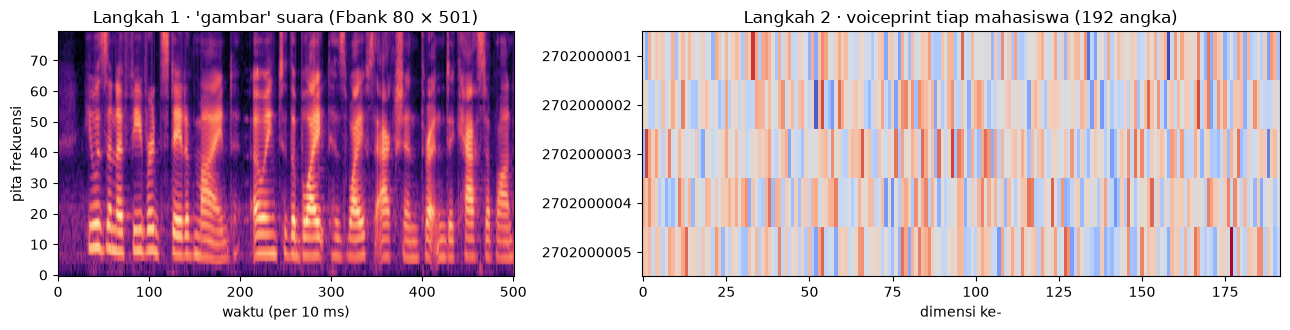

In [10]:
tampilan.gambar_fbank_dan_voiceprint(pengenal, va.muat_audio(file_contoh[0]), sistem.voiceprints)

---
## 5. Absensi

**Contoh satu percobaan:** rekaman dibandingkan dengan voiceprint NIM yang diakui, dan dengan teman sekelas yang paling mirip.

In [11]:
contoh = uji.iloc[0]
sistem.absen(DATA / contoh.file, contoh.klaim_nim).as_dict()

{'keputusan': 'HADIR',
 'alasan': 'suara cocok',
 'skor': 0.806,
 'pesaing_terdekat': '2702000002',
 'skor_pesaing': 0.288,
 'selisih': 0.518}

**Semua percobaan** di manifest. Hasilnya disimpan ke `hasil/hasil_inferensi.csv`.

🟩 HADIR   🟨 ULANGI   🟥 TOLAK

In [12]:
hasil = evaluasi.jalankan_absensi(sistem, DATA, uji)
hasil.to_csv(HASIL / "hasil_inferensi.csv", index=False)

tampilan.tabel_hasil(hasil)

file,pemilik_suara,klaim_nim,harapan,keputusan,alasan,skor,selisih,benar
audio/uji/2702000001_1.wav,2702000001,2702000001,hadir,HADIR,suara cocok,0.806,0.518,True
audio/uji/2702000001_2.webm,2702000001,2702000001,hadir,HADIR,suara cocok,0.802,0.557,True
audio/uji/2702000002_1.wav,2702000002,2702000002,hadir,HADIR,suara cocok,0.830,0.603,True
audio/uji/2702000002_2.wav,2702000002,2702000002,hadir,HADIR,suara cocok,0.823,0.609,True
audio/uji/2702000003_1.wav,2702000003,2702000003,hadir,HADIR,suara cocok,0.838,0.516,True
audio/uji/2702000003_2.wav,2702000003,2702000003,hadir,HADIR,suara cocok,0.833,0.516,True
audio/uji/2702000004_1.wav,2702000004,2702000004,hadir,HADIR,suara cocok,0.811,0.713,True
audio/uji/2702000004_2.wav,2702000004,2702000004,hadir,HADIR,suara cocok,0.821,0.706,True
audio/uji/2702000005_1.wav,2702000005,2702000005,hadir,HADIR,suara cocok,0.794,0.550,True
audio/uji/2702000005_2.wav,2702000005,2702000005,hadir,HADIR,suara cocok,0.844,0.607,True


---
## 6. Evaluasi

| Metrik | Arti | Yang diinginkan |
|---|---|---|
| **Akurasi** | Prediksi sesuai kunci jawaban | Setinggi mungkin |
| **FRR** (*False Reject Rate*) | Mahasiswa asli gagal absen | Rendah (masih bisa mengulang) |
| **FAR** (*False Accept Rate*) | Penyusup berhasil absen | **Sedekat mungkin 0%** |

In [13]:
tampilan.tabel(evaluasi.ringkasan(hasil))

metrik,arti,nilai,jumlah
Akurasi,prediksi sesuai kunci jawaban,100.0%,18/18
FRR,mahasiswa asli gagal absen,0.0%,0/10
FAR,penyusup berhasil absen,0.0%,0/7


### Sebaran skor

Setiap rekaman uji dibandingkan dengan **semua** voiceprint. Model yang baik memisahkan dua kelompok: 🟢 orang yang sama (skor tinggi) dan 🔴 orang berbeda (skor rendah).

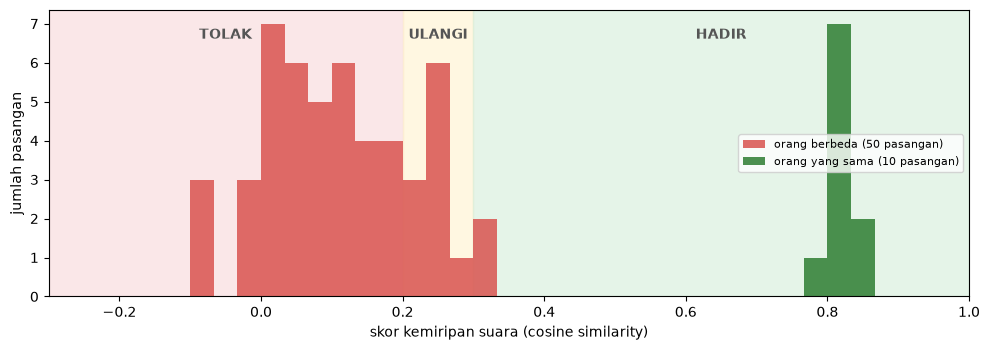

In [14]:
pasangan = evaluasi.skor_semua_pasangan(sistem, DATA, uji)
tampilan.gambar_sebaran(pasangan, pengaturan)

### Memilih ambang

Baris yang disorot adalah ambang yang dipakai sekarang. Ambang terbaik punya **FAR 0%** dan FRR serendah mungkin. Ulangi dengan rekaman kelas sungguhan sebelum dipakai.

In [15]:
daftar_ambang = [round(0.20 + 0.05 * langkah, 2) for langkah in range(11)]
tampilan.tabel_ambang(evaluasi.tabel_ambang(pasangan, daftar_ambang), pengaturan.ambang_hadir)

ambang,FRR: asli ditolak,FAR: penyusup diterima
0.20,0.0%,24.0%
0.25,0.0%,12.0%
0.30,0.0%,4.0%
0.35,0.0%,0.0%
0.40,0.0%,0.0%
0.45,0.0%,0.0%
0.50,0.0%,0.0%
0.55,0.0%,0.0%
0.60,0.0%,0.0%
0.65,0.0%,0.0%


### Pasangan suara paling mirip

Jika ada pasangan dengan skor mendekati ambang HADIR, naikkan `ambang_hadir` atau `selisih_minimal`.

In [16]:
tampilan.tabel(evaluasi.pasangan_termirip(sistem).round(3))

NIM 1,NIM 2,skor
2702000003,2702000005,0.304000
2702000001,2702000002,0.255000
2702000001,2702000005,0.250000
2702000002,2702000005,0.217000
2702000001,2702000003,0.217000


---
## 7. Coba Suara Sendiri

### Cek satu file

In [17]:
for file, nim in [
    ("audio/uji/2702000001_2.webm", "2702000001"),
    ("audio/uji/tamu_1.wav", "2702000001"),
    ("audio/uji/2702000003_pendek.wav", "2702000003"),
]:
    print(f"{file} mengaku {nim} →", sistem.absen(DATA / file, nim))

audio/uji/2702000001_2.webm mengaku 2702000001 → HADIR (suara cocok, skor 0.802)


audio/uji/tamu_1.wav mengaku 2702000001 → TOLAK (suara tidak cocok dengan NIM, skor -0.024)
audio/uji/2702000003_pendek.wav mengaku 2702000003 → ULANGI (rekaman terlalu pendek (1.2 detik))


### Rekam dari mikrofon (Colab)

1. Isi `NIM`. Pilih `JENIS = "daftar"` (rekam K01, K02, K03 satu per satu) atau `JENIS = "uji"` (absen).
2. Ubah `REKAM_SEKARANG = True`, jalankan sel, izinkan mikrofon, lalu bacakan kalimat yang muncul.
3. Rekaman disimpan dan ditambahkan ke `manifest.csv`. Untuk mahasiswa baru, tambahkan NIM ke `mahasiswa.csv` lalu jalankan ulang dari bagian 2.

> Tanpa `FOLDER_DATA_SENDIRI`, rekaman hilang saat runtime Colab berhenti.

In [18]:
REKAM_SEKARANG = False
NIM = "2702000001"
JENIS = "uji"
ID_KALIMAT = "U01"
DETIK = 5

if REKAM_SEKARANG and DI_COLAB:
    print("Bacakan:", colab.kalimat_untuk(naskah, mahasiswa, ID_KALIMAT, NIM))
    path_baru = colab.simpan_rekaman(DATA, colab.rekam_mikrofon(DETIK), NIM, JENIS, ID_KALIMAT)
    display(Audio(va.muat_audio(path_baru).numpy(), rate=16000))
    if JENIS == "uji":
        print(sistem.absen(path_baru, NIM))
else:
    print("Ubah REKAM_SEKARANG = True (di Colab) untuk merekam.")

Ubah REKAM_SEKARANG = True (di Colab) untuk merekam.


### Unggah file (Colab)

In [19]:
UNGGAH_SEKARANG = False

if UNGGAH_SEKARANG and DI_COLAB:
    from google.colab import files
    for nama_file, isi in files.upload().items():
        (HASIL / nama_file).write_bytes(isi)
        print(f"{nama_file} mengaku {NIM} →", sistem.absen(HASIL / nama_file, NIM))
else:
    print("Ubah UNGGAH_SEKARANG = True (di Colab) untuk mengunggah file.")

Ubah UNGGAH_SEKARANG = True (di Colab) untuk mengunggah file.


---
## Kesimpulan

| | |
|---|---|
| **Masalah** | Absensi manual lambat dan mudah dititipkan |
| **Solusi** | Verifikasi suara: mahasiswa membaca satu kalimat, sistem mengenali suaranya |
| **Model** | ECAPA-TDNN pretrained (SpeechBrain, PyTorch), suara → voiceprint 192 angka |
| **Keputusan** | Cosine similarity + ambang + perbandingan dengan teman sekelas paling mirip |
| **Skalabilitas** | Mahasiswa baru = tambah voiceprint, tanpa melatih ulang |
| **Keamanan** | Kode acak mencegah rekaman ulang; FAR diukur dan ambang disetel dari data |
| **Pengembangan** | *Fine-tuning* setelah data kelas cukup (±50 mahasiswa × 10 rekaman) |

> Audio contoh berasal dari **LibriSpeech** (CC BY 4.0), pembaca buku berbahasa Inggris, sebagai pengganti sampai tim merekam sendiri. NIM dan nama "Mahasiswa A–E" adalah data rekaan.